# Практика 8. Обработка текста и приложение с большой языковой моделью

**中文文本处理与大模型问答应用** · Прикладные технологии ИИ · 180 минут (3 ч.) · Модуль 4

**Цель практики:** освоить классический NLP-стек (jieba + мешок слов + TF-IDF +
наивный Байес) и **разработать небольшое приложение интеллектуальный вопрос-ответ
на базе китайских больших языковых моделей** (DeepSeek / Z.ai GLM-4.6 / Qwen),
а также **освоить приёмы оптимизации промптов** — zero-shot, few-shot и
chain-of-thought.

**Часть 1** (обязательно, офлайн): jieba, мешок слов, TF-IDF, классификатор спама.
**Часть 2** (с ключом Z.ai / DeepSeek / Qwen): настоящее приложение «вопрос-ответ»
   на китайских больших языковых моделях и оптимизация промптов.

**Бесплатные учебные ключи:**
   • **Z.ai** (рекомендуется, китайский GLM-4.6) — `https://z.ai/`
   • **DeepSeek** — `https://platform.deepseek.com` (работает в Китае без VPN)
   • **Alibaba Bailian / Qwen** — `https://bailian.console.aliyun.com/`
   Без ключа доступен демо-режим — ноутбук остаётся runnable.

**Что вы научитесь делать к концу практики:**
   • превращать китайский и русский текст в векторы (BoW, TF-IDF);
   • обучать наивный Байес на маленьком корпусе спам-писем;
   • вызывать большую языковую модель через OpenAI-совместимый API;
   • отличать плохой промпт от хорошего и применять техники
     zero-shot / few-shot / chain-of-thought.


## 📖 Введение

**Обработка естественного языка (Natural Language Processing, NLP)** — это раздел ИИ,
в котором компьютер учится *понимать*, *анализировать* и *порождать* текст на человеческом
языке. В отличие от таблиц с числами или картинок с фиксированным разрешением, текст —
особый тип данных:

- **неструктурированный** — нет готовых колонок и признаков, нужно их «добыть»;
- **дискретный** — слова не упорядочены числовой осью, расстояние между «кошкой» и «собакой»
  не равно расстоянию между «кошкой» и «компьютером»;
- **контекстно-зависимый** — «замок» может быть зданием или дверной защёлкой, и модель обязана
  это различать;
- **языково-специфичный** — у китайского нет пробелов между словами, у русского — падежи,
  у английского — строгий порядок слов.

**Классические задачи NLP:** классификация текстов (спам / не спам, тональность,
тематика), поиск похожих документов, машинный перевод, извлечение сущностей (имена,
даты, суммы), вопрос-ответ, генерация текста.

**Два поколения методов:**

1. **Классическое NLP (до 2018 г.)** — ручные признаки, мешок слов (Bag-of-Words),
   TF-IDF, наивный Байес, SVM. Текст превращается в длинный разреженный вектор счётчиков
   слов и подаётся в обычную модель машинного обучения. Дёшево, объяснимо, но «не понимает»
   смысла — для модели «кошка рядом с собакой» и «кошка далеко от собаки» — почти одно и то же.
2. **Большие языковые модели (LLM, с 2018–2022 гг.)** — нейросети-трансформеры с миллиардами
   параметров (GPT, GLM, DeepSeek, Claude и др.). Обучаются на огромных корпусах, предсказывают
   следующий токен. На выходе — не разреженный счётчик, а *плотное векторное представление*
   (embedding), в котором слова со сходным смыслом лежат рядом. LLM уже «понимают» контекст,
   стиль, формат ответа — но требуют API-вызова и стоят денег за токены.

В этой практике мы пройдём **оба пути**: сначала соберём классический спам-фильтр на мешке
слов и наивном Байесе (полностью офлайн), а затем подключимся к настоящей языковой модели
через API и научимся *управлять* её поведением через промпты.

<div style="text-align: center; margin: 16px 0;">
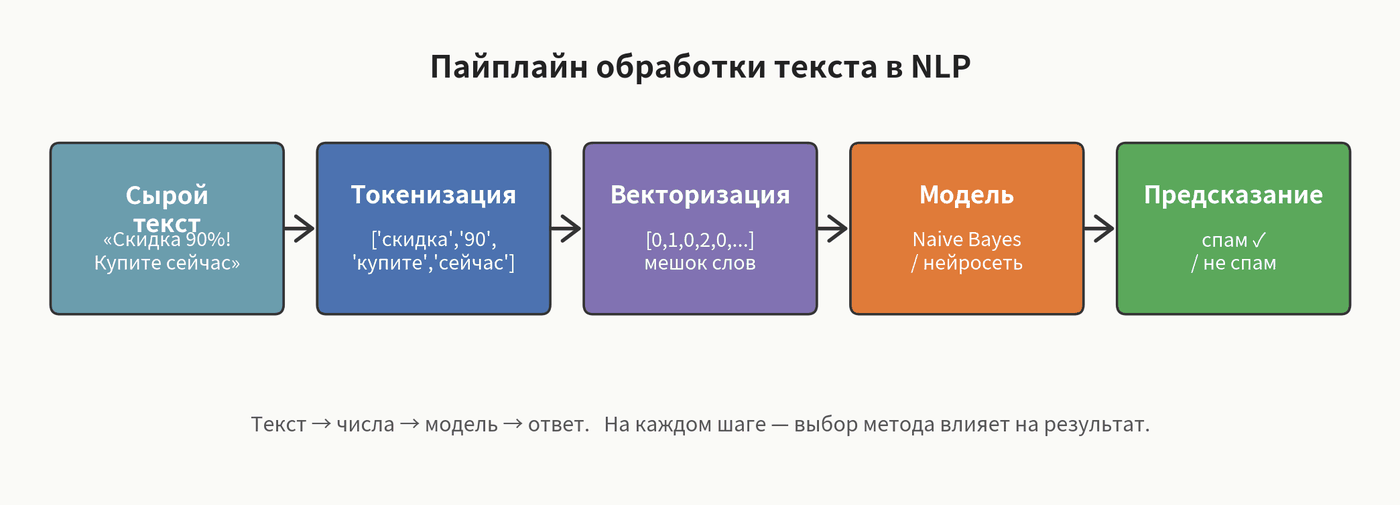
</div>


In [1]:
# Настройка ноутбука: графики внутри документа, шрифты с кириллицей и иероглифами
%matplotlib inline
import os
import numpy as np
import matplotlib.font_manager as fm
for fp in ['/usr/share/fonts/truetype/chinese/NotoSansSC-Regular.ttf']:
    if os.path.exists(fp):
        fm.fontManager.addfont(fp)
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Noto Sans SC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.15
print('Настройка завершена. Запускайте ячейки по порядку — сверху вниз.')

Настройка завершена. Запускайте ячейки по порядку — сверху вниз.


## Часть 1. Текст становится числами

### 🔤 Почему сегментация китайского текста — нетривиальная задача

В русском и английском слова отделены друг от друга пробелами — простейший `text.split()`
уже даёт осмысленные токены. В **китайском письме** пробелов между словами нет: «机器学习»
— это одно составное слово «машинное обучение», но визуально оно выглядит как строка из
четырёх иероглифов. То же самое для японского (без сегментации) и, частично, для тайского.

Поэтому первый шаг любого китайского NLP-пайплайна — **автоматическая сегментация слов**
(分词). Самый популярный инструмент — библиотека **jieba** («заика» — отсылка к тому, как
читается китайский без пробелов). Она использует:

- **словарь частот** из сотен тысяч слов,
- **алгоритм Viterbi** на основе HMM для неизвестных слов,
- **пользовательский словарь** для терминов своей предметной области
  (`jieba.load_userdict("mywords.txt")`).

**Сравнение трёх языков:**

| Язык | Фраза | `len(фраза.split())` | Реальных слов |
|---|---|---|---|
| Русский  | «Машинное обучение интересно»   | 3 | 3 |
| Английский | «Machine learning is fun»    | 4 | 4 |
| Китайский | «机器学习很有趣»               | 1 | 3 (机器 / 学习 / 很有趣) |

Сегментация — фундамент всего: ошибёшься на границах слов, и мешок слов,
и TF-IDF, и embedding получат шум. Поэтому в нашей практике jieba идёт **первым шагом**
даже перед векторизацией.


### Шаг 1. Сегментация jieba

Building prefix dict from the default dictionary ...
Loading model from cache C:\Users\1\AppData\Local\Temp\jieba.cache
Loading model cost 1.018 seconds.
Prefix dict has been built successfully.


Токены: ['人工智能', '正在', '改变', '世界', '机器', '学习', '计算机', '数据', '学习', '深度', '学习', '机器'] ...
Топ слов: [('学习', 4), ('机器', 2), ('人工智能', 1), ('正在', 1), ('改变', 1), ('世界', 1)]


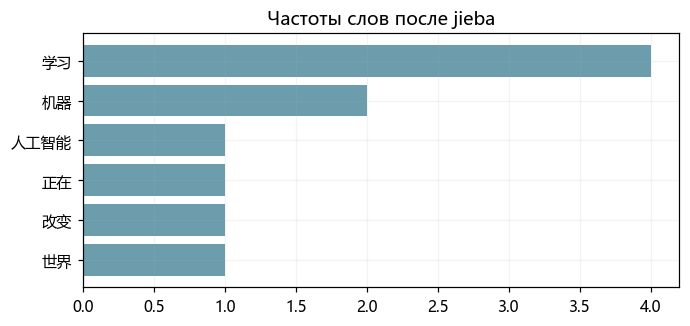

In [2]:
import jieba
from collections import Counter

text = ("人工智能正在改变世界。机器学习让计算机从数据中学习。"
        "深度学习是机器学习的一部分。大语言模型可以理解和生成文本。")
words = [w for w in jieba.cut(text) if len(w.strip()) >= 2]
print("Токены:", words[:12], "...")
top = Counter(words).most_common(6)
print("Топ слов:", top)

plt.figure(figsize=(7, 3))
plt.barh([w for w, _ in top][::-1], [n for _, n in top][::-1], color="#6B9DAD")
plt.title("Частоты слов после jieba")
plt.show()

### Шаг 2. Классификатор спама на мешке слов
Мини-корпус на трёх языках — русско-китайский курс же!

### 📊 Что такое мешок слов, TF-IDF и наивный Байес

**Мешок слов (Bag-of-Words, BoW)** — самый простой способ превратить текст в вектор:

1. Собрать **словарь** всех уникальных слов из корпуса (например, 5000 слов).
2. Для каждого документа составить вектор длины 5000, где на позиции слова стоит
   **сколько раз** оно встретилось в этом документе.
3. Порядок слов теряется — отсюда и название «мешок».

**Плюсы:** просто, быстро, работает без графического процессора.
**Минусы:** теряется порядок и смысл; векторы огромные и разреженные;
«выиграли приз» и «приз выиграли» — один и тот же вектор.

**TF-IDF (Term Frequency — Inverse Document Frequency)** — улучшение BoW: вес слова
в документе равен `TF × IDF`, где `IDF = log(N / df)` уменьшает вес частых слов
(«и», «в», «на»), которые встречаются почти везде и не несут информации. В scikit-learn
это `TfidfVectorizer` — капля замены `CountVectorizer`.

**Почему именно наивный Байес (MultinomialNB)?** Для классификации текста он —
дефолт-выбор «первой ночи»:
- работает с разреженными матрицами счётчиков (как BoW);
- обучается за доли секунды даже на миллионах документов;
- интерпретируем: для каждого слова известно, насколько оно «спамовое» или «не-спамовое»;
- наивное предположение о независимости слов — на практике работает парадоксально хорошо,
  особенно на коротких текстах.

Даже в эпоху LLM этот стек (BoW/TF-IDF + NB или логрегрессия) остаётся рабочим лошадкой
для задач вроде модерации комментариев, маршрутизации тикетов, детекции языка — там, где
важны скорость, дешевизна и воспроизводимость.

<div style="text-align: center; margin: 16px 0;">
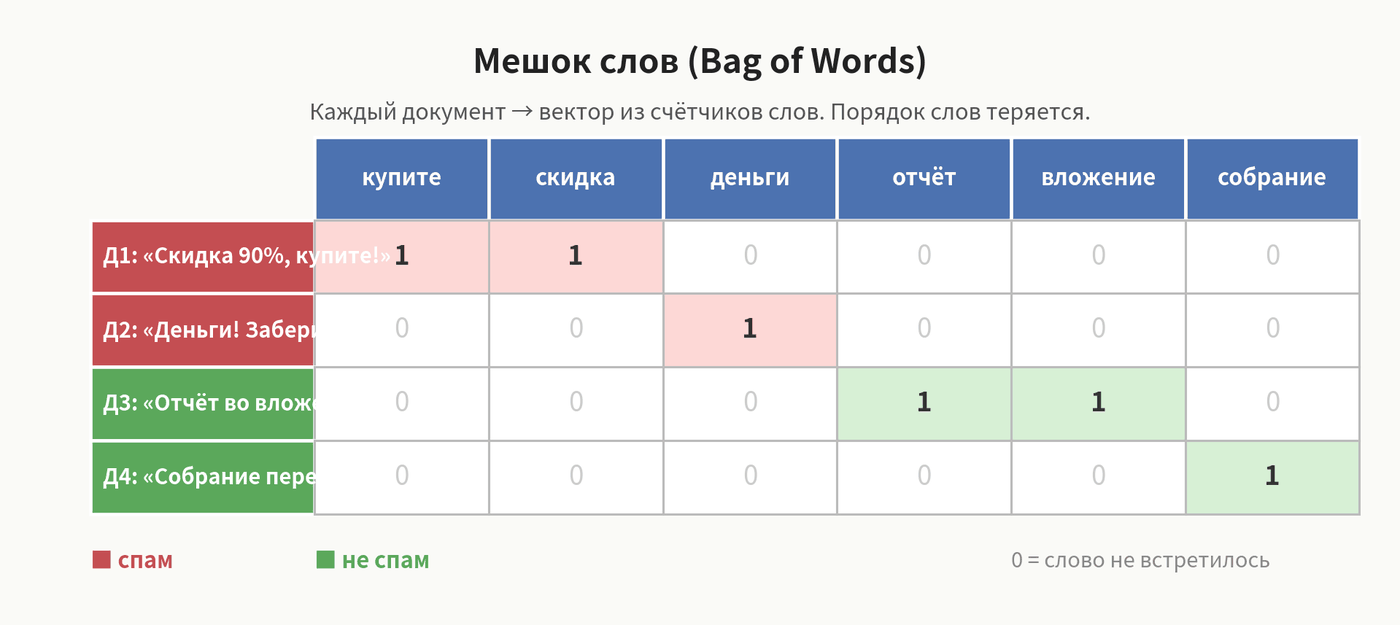
</div>


In [3]:
import warnings
warnings.filterwarnings('ignore', category=UserWarning, module='sklearn.feature_extraction.text')

import re
import numpy as np
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

messages = [
    ("Поздравляем! Вы выиграли приз, перейдите по ссылке", "спам"),
    ("Скидка 90%! Купите сейчас, осталось мало мест", "спам"),
    ("Бесплатные деньги! Забери свой выигрыш сегодня", "спам"),
    ("【抽奖】恭喜您中奖，点击链接领取", "спам"),
    ("限时优惠，立即抢购免费礼物", "спам"),
    ("Win a free iPhone, click here", "спам"),
    ("Работа на дому! Заработай 5000 в день без усилий", "спам"),
    ("Только сегодня скидка 70 на всё, успей купить", "спам"),
    ("【兼职】高薪日结，无需经验，立即加入", "спам"),
    ("Get rich fast! Guaranteed income, no risk", "спам"),
    ("Срочно! Ваш аккаунт заблокирован, восстановите доступ", "спам"),
    ("Кредит за 5 минут без справок и поручителей", "спам"),
    ("您有一份包裹无法投递，请点击更新地址", "спам"),
    ("邀请您参加免费理财讲座，座位有限", "спам"),
    ("Congratulations! You are our lucky visitor today", "спам"),
    ("Уникальная методика похудения минус 10 кг в неделю", "спам"),
    ("Казино платит мгновенно, забери бонус новичка", "спам"),
    ("【清仓】全场一折，最后三天", "спам"),
    ("Hot singles in your area want to chat now", "спам"),
    ("Ваш заказ отправлен, трек-номер в письме", "не спам"),
    ("Здравствуйте! Отчёт по проекту во вложении", "не спам"),
    ("Собрание команды перенесено на пятницу", "не спам"),
    ("会议改到明天下午三点，请准时参加", "не спам"),
    ("老师好，我的作业已经提交了", "не спам"),
    ("The lecture notes are attached, see you tomorrow", "не спам"),
    ("午餐一起去食堂吗？", "не спам"),
    ("提醒：明天下午实验课，带上笔记本", "не спам"),
    ("Спасибо за помощь с лабораторной!", "не спам"),
    ("Library books are due next Monday", "не спам"),
    ("Деканат: справки можно заказать онлайн до пятницы", "не спам"),
    ("Пекарня на углу открылась, кофе бесплатно по акции", "не спам"),
    ("快递已放在楼下柜子，取件码 3391", "не спам"),
    ("周末一起去爬山吗？", "не спам"),
    ("Can we reschedule our call to Thursday morning?", "не спам"),
    ("Мама передаёт привет и спрашивает, когда приедешь", "не спам"),
    ("Поздравляю с днём рождения, желаю счастья!", "не спам"),
    ("作业在附件里，请老师查收", "не спам"),
    ("Your subscription to the journal expires soon", "не спам"),
]
texts  = [m for m, _ in messages]
labels = [l for _, l in messages]

def tokenize(t):
    clean = re.sub(r"[^\w\s]", "", t.lower())
    return [w for w in jieba.cut(clean) if w.strip()]

vectorizer = CountVectorizer(tokenizer=tokenize, token_pattern=None)
X = vectorizer.fit_transform(texts)
print("Матрица мешок слов:", X.shape, "| словарь:", len(vectorizer.vocabulary_), "слов")

X_tr, X_te, y_tr, y_te = train_test_split(X, labels, test_size=6, random_state=7,
                                           stratify=labels)
clf = MultinomialNB().fit(X_tr, y_tr)
pred = clf.predict(X_te)
print(f"Точность классификатора спама: {accuracy_score(y_te, pred):.0%}")
print("Мораль: корпус крошечный — при другом разбиении точность скачет.")
print("Вот почему данные — топливо ИИ: качества мало без количества.")

for msg in ["Вы выиграли миллион, жмите сюда!", "明天交作业，请查收附件"]:
    print(f"«{msg}» ->", clf.predict(vectorizer.transform([msg]))[0])


Матрица мешок слов: (38, 162) | словарь: 162 слов
Точность классификатора спама: 83%
Мораль: корпус крошечный — при другом разбиении точность скачет.
Вот почему данные — топливо ИИ: качества мало без количества.
«Вы выиграли миллион, жмите сюда!» -> спам
«明天交作业，请查收附件» -> не спам


### 🧭 От разреженного мешка к плотному embedding

Классический BoW даёт векторы из тысяч нулей и нескольких единиц — они **разреженные**
и не передают семантику. Современные методы превращают каждое слово или предложение
в **плотный вектор** небольшой размерности (например, 768 или 1536 чисел) — **embedding**
(«вложение», «вложенное представление»).

Такие векторы обучаются так, чтобы слова со **сходным смыслом** имели близкие векторы
(по косинусному расстоянию). LLM «думает» именно в этом пространстве: входной токен
сначала превращается в свой embedding, потом через десятки слоёв трансформера контекст
смешивается, и на выходе снова получается распределение вероятностей токенов.

На картинке ниже — упрощённая 2D-проекция. Заметьте:

- «машинное обучение», «ИИ», «нейросеть», «трансформер» лежат кучно в одном кластере;
- «футбол», «теннис», «марафон» — в другом, далеко от первого;
- «пицца», «суши» — третий кластер, ещё дальше.

Именно эта геометрическая близость позволяет LLM понимать, что «машинное обучение»
ближе к «ИИ», чем к «спорту», даже если у этих пар нет общих букв. Классический BoW
такого бы не дал: у «ИИ» и «машинного обучения» в мешке слов может быть ноль общих слов,
и их векторы были бы полностью ортогональны.

<div style="text-align: center; margin: 16px 0;">
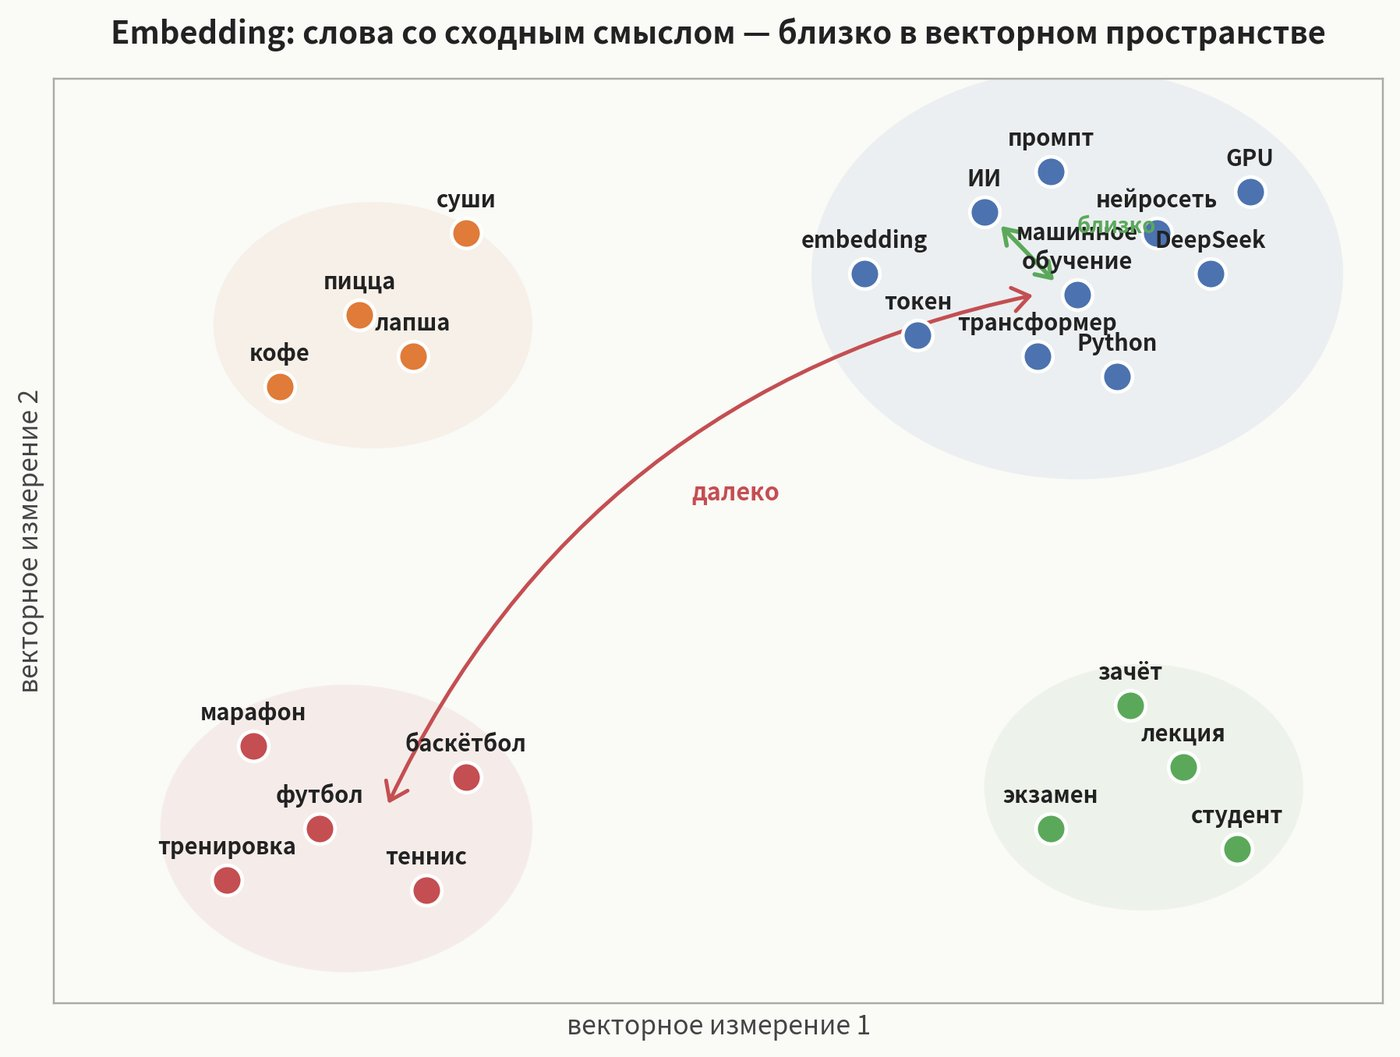
</div>


## Часть 2. Приложение «вопрос-ответ» на китайских больших языковых моделях

Классический стек (BoW + NB) хорош для классификации, но **порождать** связный
текст, отвечать на свободные вопросы и переводить он не умеет — это уже задача
**больших языковых моделей (LLM)**. Во второй части практики мы:

1. Подключимся к китайской LLM через OpenAI-совместимый API
   (Z.ai GLM-4.6, DeepSeek-V3 или Qwen).
2. Соберём мини-приложение «интеллектуальный вопрос-ответ» с историей диалога
   и двумя режимами промпта (простой / инженерный).
3. Проведём эксперимент с оптимизацией промптов: zero-shot → few-shot →
   chain-of-thought, и сравним плохой промпт с хорошим.


### Шаг 3. Клиент к модели
Функция честная: с ключом обращается к DeepSeek, без ключа — демо-режим.

### 🤖 Что такое LLM и как работает API

**Большая языковая модель (Large Language Model, LLM)** — это нейросеть-трансформер
с миллиардами параметров, обученная предсказывать следующий токен в тексте. На
выходе она умеет *порождать* связный текст в нужном стиле, отвечать на вопросы,
переводить, писать код.

**Три основные китайские LLM, которые мы используем в этой практике:**

| Модель | Разработчик | Особенности | Base URL для API |
|---|---|---|---|
| **GLM-4.6** | Z.ai (智谱, Tsinghua spin-off) | Сильна в рассуждениях и русском языке, бесплатный учебный доступ | `https://api.z.ai/api/v1` или `https://open.bigmodel.cn/api/paas/v4/` |
| **DeepSeek-V3** | DeepSeek (深度求索) | Очень дешёвый API, открытые веса (open-weights), лидер в reasoning | `https://api.deepseek.com` |
| **Qwen 2.5 / Qwen 3** | Alibaba (通义千问) | Сильная многоязычность, семья моделей на любой размер | `https://dashscope.aliyuncs.com/compatible-mode/v1` |

**Чем они отличаются друг от друга?**

- **GLM (Z.ai)** — выросла из лаборатории Цинхуа, целенаправленно оптимизирована под
  диалог и инструмент-вызовы (function calling). У Z.ai есть щедрый бесплатный
  учебный пакет, что делает её удобной для студенческих проектов.
- **DeepSeek** — стартап из Ханчжоу, выпускающий модели с открытыми весами
  (можно скачать и развернуть локально). API самый дешёвый на рынке; модель
  особенно сильна в математике и программировании благодаря
  MoE-архитектуре (Mixture-of-Experts).
- **Qwen** — серия моделей Alibaba; покрыты размерами от 0.5B до 110B параметров,
  отлично работают с китайским, английским и русским. Через сервис
  Alibaba Bailian доступен OpenAI-совместимый endpoint.

Все три провайдера приняли **OpenAI-совместимый протокол** — поэтому в коде мы
используем одну и ту же библиотеку `openai`, меняя только `base_url` и `api_key`.

**Как устроен API-вызов:**

```python
from openai import OpenAI
client = OpenAI(api_key=os.environ["ZAI_API_KEY"],
                base_url="https://api.z.ai/api/v1")
resp = client.chat.completions.create(
    model="glm-4.6",
    messages=[
        {"role": "system", "content": "Ты — ассистент курса ИИ."},
        {"role": "user",   "content": "Объясни, что такое embedding."},
    ],
    temperature=0.7,   # 0 = детерминированно, 1 = креативно
    max_tokens=250,    # максимум в ответе
)
print(resp.choices[0].message.content)
```

**Ключевые параметры:**

- `messages` — список реплик диалога: `system` (роль/инструкция), `user` (вопрос),
  `assistant` (предыдущие ответы) — это и есть «история диалога»;
- `temperature` — «температура» сэмплинга: `0` → всегда один и тот же ответ,
  `0.7` → умеренная вариативность, `1+` → креатив, но нестабильно;
- `max_tokens` — верхняя граница длины ответа (за токены платят);
- `model` — название модели на стороне провайдера.

**Главное отличие от классических моделей.** BoW + Naive Bayes — это *обучение на ваших
данных*: вы сами собрали корпус, обучили классификатор, он живёт в вашем ноутбуке.
LLM — это *вызов удалённого сервиса*: модель уже обучена на гигантском корпусе и стоит
деньги за каждый запрос (по числу токенов). Поэтому даже в учебном ноутбуке всегда
делают **демо-режим**: если ключа нет — возвращают заглушку, чтобы код не падал.

<div style="text-align: center; margin: 16px 0;">
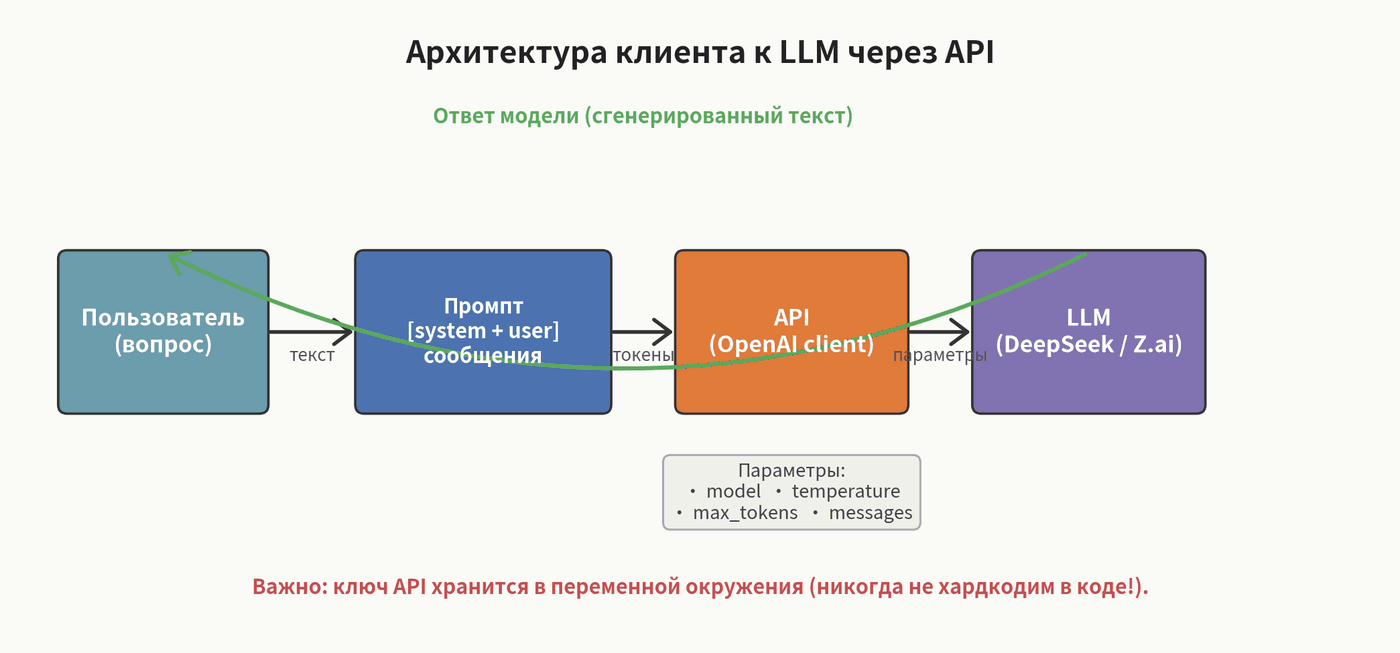
</div>

> ⚠️ **Безопасность ключей.** Никогда не пишите API-ключ прямо в коде и не коммитьте его в git.
> Храните ключи в переменных окружения (`export ZAI_API_KEY=...`) или в `.env` файле,
> добавленном в `.gitignore`.


In [4]:
import os

def ask_llm(user_text, system="Ты — ассистент курса «Технологии ИИ». "
                             "Отвечай кратко и по-русски.",
            model=None, temperature=0.7, max_tokens=250,
            examples=None):
    """Универсальный клиент к китайским LLM через OpenAI-совместимый API.

    Приоритет ключей (какая переменная окружения задана):
      1. ZAI_API_KEY        -> https://api.z.ai/api/v1            (модель glm-4.6)
      2. DEEPSEEK_API_KEY   -> https://api.deepseek.com           (модель deepseek-chat)
      3. DASHSCOPE_API_KEY  -> https://dashscope.aliyuncs.com/    (модель qwen-plus)

    Если ни одного ключа нет — возвращается демо-ответ,
    чтобы ноутбук оставался runnable без ключа.

    Параметр `examples` позволяет передать few-shot образцы —
    список кортежей (user_example, assistant_example).
    """
    zai_key = os.environ.get("ZAI_API_KEY", "")
    ds_key  = os.environ.get("DEEPSEEK_API_KEY", "")
    qwen_key = os.environ.get("DASHSCOPE_API_KEY", "")

    if not (zai_key or ds_key or qwen_key):
        snippet = user_text[:60].replace("\n", " ")
        suffix = ""
        if examples:
            suffix = f"\n[демо: few-shot с {len(examples)} образцами]"
        return ("[демо-режим] Ассистент получил бы запрос: "
                + snippet + "..." + suffix +
                "\n(задайте ZAI_API_KEY / DEEPSEEK_API_KEY / DASHSCOPE_API_KEY)")

    from openai import OpenAI
    if zai_key:
        client = OpenAI(api_key=zai_key, base_url="https://api.z.ai/api/v1")
        model  = model or "glm-4.6"
    elif ds_key:
        client = OpenAI(api_key=ds_key, base_url="https://api.deepseek.com")
        model  = model or "deepseek-chat"
    else:  # qwen
        client = OpenAI(api_key=qwen_key,
                        base_url="https://dashscope.aliyuncs.com/compatible-mode/v1")
        model  = model or "qwen-plus"

    messages = [{"role": "system", "content": system}]
    if examples:
        for u, a in examples:
            messages.append({"role": "user",      "content": u})
            messages.append({"role": "assistant", "content": a})
    messages.append({"role": "user", "content": user_text})

    resp = client.chat.completions.create(
        model=model,
        messages=messages,
        max_tokens=max_tokens, temperature=temperature)
    return resp.choices[0].message.content

# Обратная совместимость со старым именем
ask_deepseek = ask_llm

print(ask_llm("Что такое переобучение?"))


[демо-режим] Ассистент получил бы запрос: Что такое переобучение?...
(задайте ZAI_API_KEY / DEEPSEEK_API_KEY / DASHSCOPE_API_KEY)


### Шаг 4. Мини-приложение: ассистент-переводчик
Соберём «умный вопрос-ответ» с историей диалога и двумя режимами промпта.

In [5]:
def smart_assistant(question, mode="простой"):
    """Мини-приложение: система-промпт + вопрос + формат ответа."""
    if mode == "простой":
        system = "Ты — ассистент. Ответь на вопрос."
        user = question
    else:  # "инженерный": роль + контекст + формат
        system = ("Ты — преподаватель курса ИИ для китайских студентов-новичков. "
                  "Отвечай по схеме: 1) ответ одним предложением; "
                  "2) бытовая аналогия; 3) пример из китайских приложений.")
        user = question
    return ask_llm(user, system=system)

q = "Зачем нормализовать признаки перед методом ближайших соседей?"
print("=== простой промпт ===")
print(smart_assistant(q, "простой")[:300])
print("\n=== инженерный промпт ===")
print(smart_assistant(q, "инженерный")[:300])


=== простой промпт ===
[демо-режим] Ассистент получил бы запрос: Зачем нормализовать признаки перед методом ближайших соседей...
(задайте ZAI_API_KEY / DEEPSEEK_API_KEY / DASHSCOPE_API_KEY)

=== инженерный промпт ===
[демо-режим] Ассистент получил бы запрос: Зачем нормализовать признаки перед методом ближайших соседей...
(задайте ZAI_API_KEY / DEEPSEEK_API_KEY / DASHSCOPE_API_KEY)


### Шаг 5. Эксперимент с промптами (главный навык практики)

Один и тот же вопрос — несколько разных промптов. Мы сравним три техники:

* **Zero-shot** — простой запрос без примеров («объясни CNN»).
* **Few-shot** — в промпт добавлены 2–3 образца «вход → желаемый выход»,
  модель копирует стиль и формат ответа.
* **Chain-of-Thought (CoT)** — модель просят *рассуждать пошагово*
  («сначала проанализируй, потом ответь»), что особенно полезно для
  арифметики, логики и многошагового вывода.

В демо-режиме сравниваем структуру запросов; с реальным ключом — настоящие
ответы модели. Ниже — как плохой промпт превращается в хороший по правилу
**RAFR** (Role · Audience · Format · Reference).


### 🎯 Промпт-инжиниринг: язык программирования для LLM

**Промпт-инжиниринг (prompt engineering)** — это искусство составлять запросы к LLM
так, чтобы получать нужный результат с первого раза. В отличие от классического ML,
где вы обучаете модель на данных, здесь вы не трогаете веса — вы *описываете задачу
на естественном языке*. Промпт — это «программа» для LLM, только вместо Python —
обычные предложения.

**Базовые техники:**

| Техника | Что это | Когда применять |
|---|---|---|
| **Zero-shot**     | Простой запрос без примеров | простые задачи, модель уже умеет |
| **Few-shot**      | В промпт добавляют 2–5 примеров «вход → желаемый выход» | нестандартный формат, классы, стиль |
| **Chain-of-Thought** | Просим модель «думать по шагам»: «Пусть рассуждает пошагово» | арифметика, логика, выводы |
| **Role prompting**    | Назначаем роль: «Ты — опытный преподаватель ИИ» | задать тон и уровень детализации |
| **Format prompting**  | Указываем формат: «3 пункта по ≤15 слов каждый» | структурированный, предсказуемый ответ |

**Хороший промпт обычно содержит 4 элемента (мнемоника RAFR):**

1. **R**ole — роль: кем должна быть модель («преподаватель ИИ для первокурсников»);
2. **A**udience — аудитория: для кого ответ («китайские студенты-новички»);
3. **F**ormat — формат: как должен выглядеть ответ («3 пункта, по 15 слов»);
4. **R**eference / example — пример или контекст: «пример из китайских приложений».

#### ❌ Плохой промпт → ✅ Хороший промпт (RU)

**Плохо:**
> `Расскажи про нейросети.`

*Нет роли, нет формата, нет аудитории — модель начнёт писать «в среднем по больнице».*

**Хорошо:**
> `Ты — преподаватель курса ИИ для китайских студентов-первокурсников, говорящих
> по-русски. Объясни, что такое нейросеть, в 3 пунктах по ≤15 слов каждый.
> В конце приведи бытовой пример из китайских приложений (WeChat / Douyin).`

#### ❌ Плохой промпт → ✅ Хороший промпт (ZH)

**不好:**
> `解释一下深度学习。`

**好:**
> `你是面向中国大一新生的AI课程老师，用中文解释什么是深度学习。
> 要求：1）一句话定义；2）一个日常类比；3）一个中文App里的例子（如抖音推荐）。
> 每点不超过30个汉字。`

#### Few-shot пример (модель учится по образцам)

В few-shot мы добавляем в `messages` 2–3 пары `user → assistant`. Модель копирует
стиль и формат ответа:

```python
examples = [
    ("CNN — это…",   "Свёрточная нейросеть для изображений: вытаскивает признаки через фильтры."),
    ("RNN — это…",   "Рекуррентная нейросеть для последовательностей: помнит предыдущие токены."),
]
ask_llm("Transformer — это…", examples=examples)
```

#### Chain-of-Thought (CoT) — рассуждение по шагам

Для задач с логикой или арифметикой в промпт добавляют магическую фразу
«**Думай пошагово**» / «**Let's think step by step**» — это заставляет модель
выписать промежуточные шаги, что кардинально повышает точность:

> **Вопрос.** В аудитории 5 рядов по 8 стульев. Заняли 3 ряда целиком и 4 стула
> в четвёртом. Сколько свободных стульев осталось?
>
> **Промпт.** `Реши задачу. Сначала рассуждай пошагово, потом запиши ответ.`

Ниже — три варианта промпта «Объясни CNN». Сравните, насколько по-разному они
задают рамки ответа:

<div style="text-align: center; margin: 16px 0;">
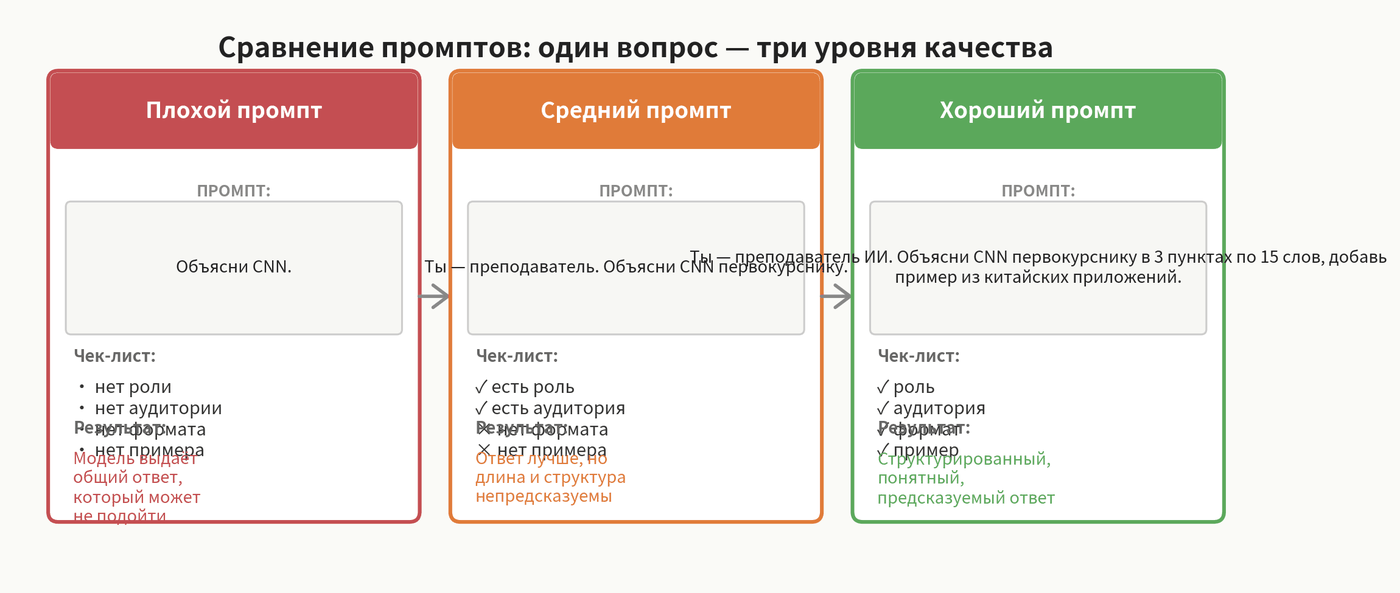
</div>

**Практический совет:** всегда начинайте с самого простого промпта, посмотрите на ответ,
и улучшайте итеративно. Дешёвая итерация — ваше преимущество перед классическим ML,
где каждый «прогон» — это переобучение модели.


In [6]:
# ----- 1. Zero-shot: один и тот же вопрос, три уровня промпта -----
prompts = {
    "плохой (без контекста)": "Расскажи про нейросети.",
    "средний (с ролью)":     "Ты — преподаватель. Расскажи первокурснику про нейросети.",
    "хороший (RAFR)":        ("Ты — преподаватель курса ИИ для китайских студентов-первокурсников. "
                              "Объясни, что такое нейросеть, в 3 пунктах по <=15 слов каждый. "
                              "В конце приведи пример из китайских приложений (WeChat / Douyin)."),
}
for name, p in prompts.items():
    print(f"--- {name} ---")
    print(p)
    # Раскомментируйте для реальных ответов:
    # print("Ответ:", ask_llm(p)[:300])
    print("Ответ модели начался бы здесь...\n")

# ----- 2. Few-shot: модель учится по 2-3 образцам стилю ответа -----
few_shot_examples = [
    ("CNN — это…",
     "Свёрточная нейросеть для изображений: вытаскивает признаки через фильтры."),
    ("RNN — это…",
     "Рекуррентная нейросеть для последовательностей: помнит предыдущие токены."),
    ("Transformer — это…",
     "Нейросеть с механизмом внимания: связывает каждый токен со всеми остальными."),
]
print("=== Few-shot: модель копирует стиль и длину образцов ===")
print("Запрос:  'GAN — это…'")
print("Ожидаемый стиль: одно предложение в <=15 слов, без воды.")
# print("Ответ:", ask_llm("GAN — это…", examples=few_shot_examples)[:200])

# ----- 3. Chain-of-Thought: рассуждаем пошагово для арифметики -----
math_question = (
    "В аудитории 5 рядов по 8 стульев. Заняли 3 ряда целиком "
    "и 4 стула в четвёртом. Сколько свободных стульев осталось?"
)
cot_system = ("Ты — преподаватель математики. Сначала рассуждай пошагово "
              "(выпиши промежуточные действия), затем запиши финальный ответ "
              "в формате 'Ответ: N'.")
plain_system = "Ты — преподаватель математики. Дай ответ."

print("\n=== Chain-of-Thought vs обычный промпт ===")
print("Вопрос:", math_question)
print("\n[без CoT, system]:", plain_system)
# print("Ответ:", ask_llm(math_question, system=plain_system)[:200])
print("\n[с CoT, system]:", cot_system)
# print("Ответ:", ask_llm(math_question, system=cot_system, max_tokens=400)[:400])
print("\n(раскомментируйте строки выше, чтобы получить реальные ответы модели)")


--- плохой (без контекста) ---
Расскажи про нейросети.
Ответ модели начался бы здесь...

--- средний (с ролью) ---
Ты — преподаватель. Расскажи первокурснику про нейросети.
Ответ модели начался бы здесь...

--- хороший (RAFR) ---
Ты — преподаватель курса ИИ для китайских студентов-первокурсников. Объясни, что такое нейросеть, в 3 пунктах по <=15 слов каждый. В конце приведи пример из китайских приложений (WeChat / Douyin).
Ответ модели начался бы здесь...

=== Few-shot: модель копирует стиль и длину образцов ===
Запрос:  'GAN — это…'
Ожидаемый стиль: одно предложение в <=15 слов, без воды.

=== Chain-of-Thought vs обычный промпт ===
Вопрос: В аудитории 5 рядов по 8 стульев. Заняли 3 ряда целиком и 4 стула в четвёртом. Сколько свободных стульев осталось?

[без CoT, system]: Ты — преподаватель математики. Дай ответ.

[с CoT, system]: Ты — преподаватель математики. Сначала рассуждай пошагово (выпиши промежуточные действия), затем запиши финальный ответ в формате 'Ответ: N'.

(раскомментир

## Задания

In [7]:
# ЗАДАНИЕ 1. Своя фраза для jieba: сегментируйте любимую китайскую пословицу
# и подсчитайте число токенов
my_tokens = None     # TODO: list(jieba.cut("ваша фраза"))

if my_tokens is None:
    print("Задание 1 не выполнено: впишите свою фразу.")
else:
    print("Токены:", my_tokens, "| всего:", len(my_tokens))

Задание 1 не выполнено: впишите свою фразу.


In [8]:
# ЗАДАНИЕ 2. Свой спам-фильтр: добавьте в messages 2 своих письма (1 спам, 1 не спам)
# и проверьте классификацию своей фразы
my_verdict = None    # TODO: вердикт модели для вашей новой фразы

if my_verdict is None:
    print("Задание 2 не выполнено.")
else:
    print("Вердикт фильтра:", my_verdict)

Задание 2 не выполнено.


In [9]:
# ЗАДАНИЕ 3. Промпт-инженерия: улучшите запрос «Объясни CNN» так,
# чтобы получить: роль, аудиторию, формат (3 пункта), пример из жизни.
# Впишите свой промпт и (если есть ключ) ответ модели.
my_prompt = None     # TODO: строка вашего промпта

if my_prompt is None:
    print("Задание 3 не выполнено: напишите улучшенный промпт.")
else:
    print("Ваш промпт:\n", my_prompt)
    # print(ask_deepseek(my_prompt))   # раскомментируйте при наличии ключа

Задание 3 не выполнено: напишите улучшенный промпт.


## Критерии оценки

| Критерий | Баллы |
|---|---|
| Шаги 1–2: jieba + спам-классификатор работают | 35 |
| Шаги 3–5: структура API и промптов разобрана | 15 |
| Задание 1: своя сегментация | 10 |
| Задание 2: свои письма + вердикт | 15 |
| Задание 3: инженерный промпт по всем 4 правилам RAFR | 15 |
| Реальный вызов Z.ai / DeepSeek / Qwen (при наличии ключа) | +10 бонус |
| **Итого** | **100 (+10)** |

## Что отправить преподавателю
Ноутбук + ваш лучший промпт и объяснение, почему он лучше исходного.
Обязательно укажите, какую технику вы применили (zero-shot / few-shot / CoT).


## 🎓 Итоги Практики 8

Мы прошли **весь путь** от сырого текста до работающего приложения с LLM:

1. **Сегментация.** На примере jieba увидели, что для китайского текста `split()` не работает —
   границу слов нужно находить алгоритмически. Это фундамент любого китайского NLP.

2. **Векторизация.** Превратили текст в числа через мешок слов и `CountVectorizer`,
   а также обсудили **TF-IDF** — улучшение BoW, уменьшающее вес частых слов.
   Поняли ограничения: теряются порядок, контекст, смысл.

3. **Классификация.** Обучили наивный Байес на крошечном корпусе — точность зависит
   от разбиения, поэтому *качество данных важнее хитрой модели*. Это был наш «классический» baseline.

4. **Embedding.** Увидели разницу между разреженным счётчиком и плотным векторным
   пространством, где слова со схожим смыслом лежат рядом. На этом и «думают» LLM.

5. **LLM и API.** Подключились к **китайской большой языковой модели** через
   OpenAI-совместимый API — Z.ai GLM-4.6, DeepSeek-V3 или Qwen. Освоили структуру
   запроса: `system`-промпт, история диалога, `temperature`, `max_tokens`, `examples`.
   Увидели, что LLM — это сервис, а не обученная локально модель. Собрали мини-приложение
   **интеллектуальный вопрос-ответ** в двух режимах: простой и инженерный.

6. **Оптимизация промптов.** Сравнили плохой, средний и хороший промпты.
   Запомнили мнемонику **RAFR**: роль, аудитория, формат, пример.
   Освоили три техники: **zero-shot** (просто спросить), **few-shot** (показать 2–3
   образца нужного стиля) и **chain-of-thought** (попросить рассуждать пошагово —
   особенно для арифметики и логики).

**Главный вывод курса:** классическое NLP (BoW + NB) и LLM — не конкуренты, а
инструменты разного назначения. BoW дёшев, объясним, работает офлайн — подходит для
модерации, маршрутизации, baseline. LLM дорогой, но универсальный и «понимающий» —
его место там, где нужно породить текст или рассуждать. Уметь выбрать нужный
инструмент под задачу — и есть квалификация прикладного инженера ИИ.
